In [15]:
import pandas as pd
import numpy as np 

import seaborn as sns 
import matplotlib.pylab as plt
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge,Lasso,ElasticNet
from sklearn.metrics import r2_score 
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import scale
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.decomposition import PCA



In [16]:
data = pd.read_csv("student_performance_dataset.csv", skipinitialspace=True)
data.head()

,student_id,age,gender,city_type,study_hours_per_day,deep_work_sessions,assignment_completion_rate,attendance_percentage,social_media_hours,doomscrolling_before_sleep,...,family_support,financial_stress,learning_style,career_goal,productivity_after_midnight,revision_efficiency,burnout_risk,consistency_score,final_exam_score,performance_category
0,0,21,Female,Semi-Urban,3.2,7,100,70,3.8,0,...,10,6,Audio,Engineering,9,1,10,3,32,Low
1,1,19,Female,Semi-Urban,3.9,2,46,70,2.6,1,...,2,6,Practical,Business,6,10,4,6,59,Medium
2,2,16,Female,Urban,4.3,7,54,57,4.3,1,...,1,9,Visual,Engineering,7,9,8,1,34,Low
3,3,19,Male,Semi-Urban,5.3,1,78,90,1.7,0,...,5,10,Reading,Medical,7,7,9,10,60,Medium
4,4,17,Female,Urban,4.1,3,100,81,2.6,0,...,5,6,Visual,Medical,4,10,7,9,77,High


## Exploratory Data Analysis and Feature Engineering

This section profiles the original dataset before dropping rows or columns. It summarizes data quality, target distribution, numeric relationships, and engineered features. `student_id` is an identifier and `performance_category` is derived from the exam-score target, so neither is used as a predictor. Missing values remain visible during exploration; fit any imputation and encoding steps on training data only when modeling.

Rows: 3,000 | Columns: 32 | Duplicate rows: 0


C:\Users\hemro\AppData\Local\Temp\ipykernel_11180\945302118.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in eda.select_dtypes(include="object").columns:


,missing values
focus_score,60
social_media_hours,60
sleep_hours,60


,final_exam_score
count,3000.000000
mean,54.795667
std,18.691309
min,0.000000
25%,42.000000
50%,55.000000
75%,67.000000
max,100.000000


,students
category,
Medium,1360
Low,1196
High,444


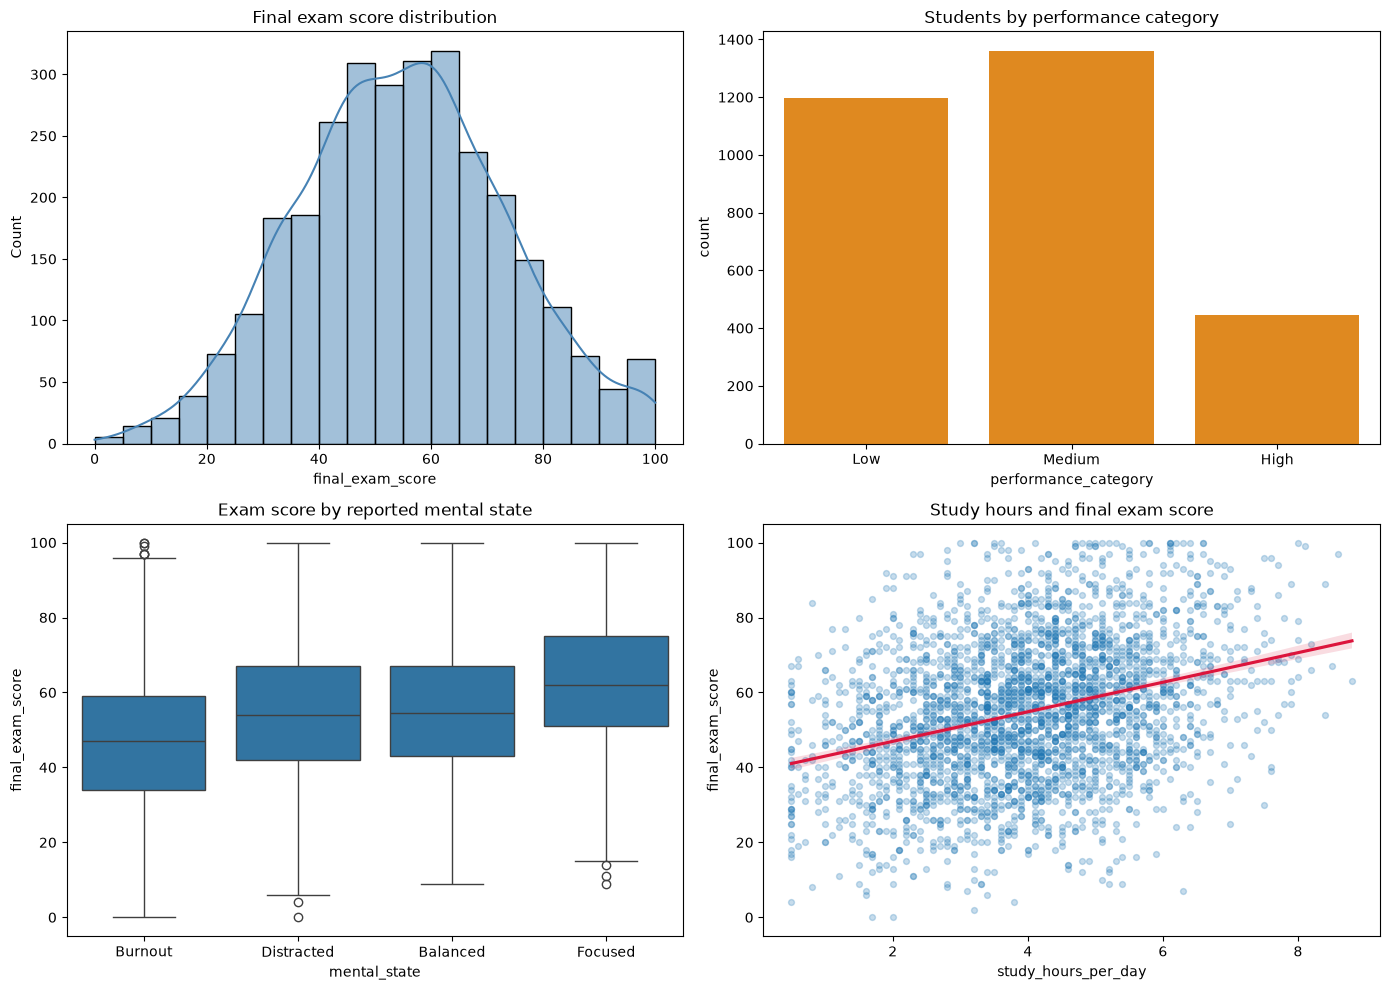

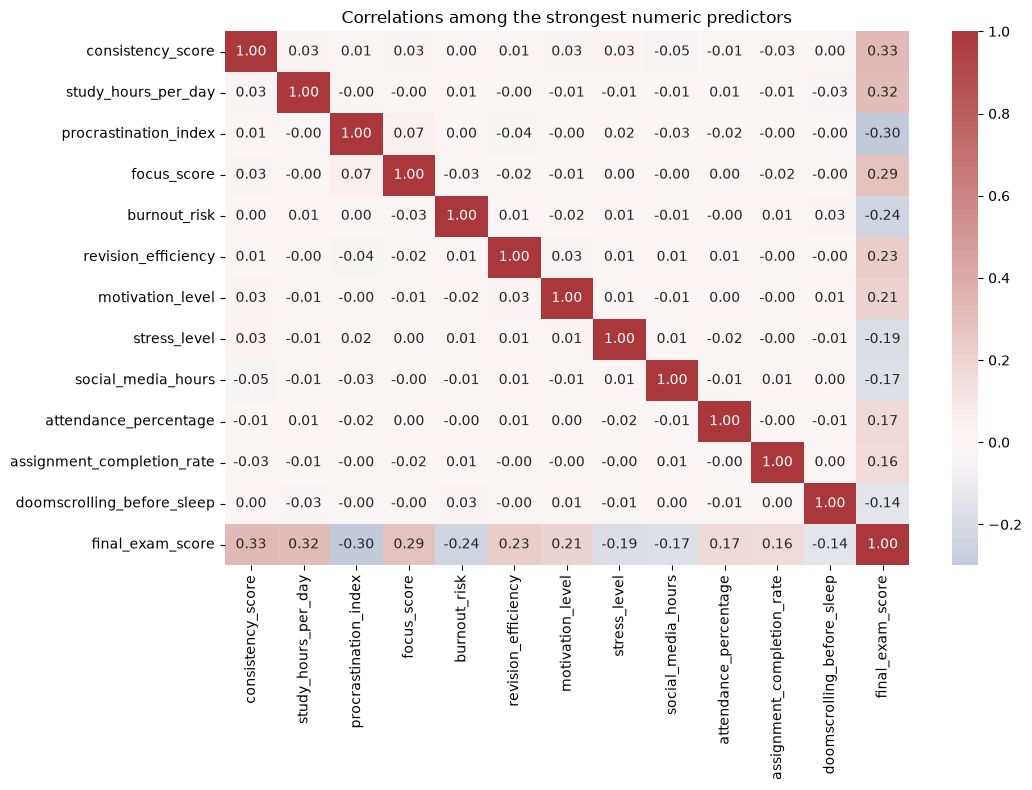

In [17]:
from pathlib import Path
eda_plot_dir = Path("eda_plots")
eda_plot_dir.mkdir(exist_ok=True)
eda = pd.read_csv("student_performance_dataset.csv", skipinitialspace=True)
eda.columns = eda.columns.str.strip()
for column in eda.select_dtypes(include="object").columns:
    eda[column] = eda[column].map(lambda value: value.strip() if isinstance(value, str) else value)
    eda[column] = eda[column].replace("", np.nan)
    numeric_values = pd.to_numeric(eda[column], errors="coerce")
    if numeric_values.notna().sum() == eda[column].notna().sum():
        eda[column] = numeric_values

print(f"Rows: {len(eda):,} | Columns: {eda.shape[1]} | Duplicate rows: {eda.duplicated().sum()}")
display(eda.isna().sum().sort_values(ascending=False).loc[lambda counts: counts.gt(0)].to_frame("missing values"))
display(eda["final_exam_score"].describe().to_frame("final_exam_score"))
display(eda["performance_category"].value_counts().rename_axis("category").to_frame("students"))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(data=eda, x="final_exam_score", bins=20, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Final exam score distribution")
sns.countplot(data=eda, x="performance_category", order=["Low", "Medium", "High"], ax=axes[0, 1], color="darkorange")
axes[0, 1].set_title("Students by performance category")
sns.boxplot(data=eda, x="mental_state", y="final_exam_score", order=eda.groupby("mental_state")["final_exam_score"].median().sort_values().index, ax=axes[1, 0])
axes[1, 0].set_title("Exam score by reported mental state")
sns.regplot(data=eda, x="study_hours_per_day", y="final_exam_score", scatter_kws={"alpha": 0.25, "s": 18}, line_kws={"color": "crimson"}, ax=axes[1, 1])
axes[1, 1].set_title("Study hours and final exam score")
fig.tight_layout()
fig.savefig(eda_plot_dir / "eda_overview.png", dpi=150, bbox_inches="tight")
plt.show()

numeric_for_corr = eda.select_dtypes(include="number").drop(columns="student_id")
top_corr_features = numeric_for_corr.corr()["final_exam_score"].drop("final_exam_score").abs().nlargest(12).index
plt.figure(figsize=(11, 8))
sns.heatmap(numeric_for_corr[list(top_corr_features) + ["final_exam_score"]].corr(), cmap="vlag", center=0, annot=True, fmt=".2f")
plt.title("Correlations among the strongest numeric predictors")
plt.tight_layout()
plt.savefig(eda_plot_dir / "numeric_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

### Engineered features

The new variables combine related behaviors while retaining interpretable units: revision-adjusted study hours, focus-adjusted study hours, combined social-media and gaming hours, sleep shortfall relative to an 8-hour reference, a completion/attendance/consistency average, and a family-support minus financial-stress balance. These are exploratory candidates, not claims of causation. The derived performance label and student identifier are excluded to avoid target leakage.

,count,mean,std,min,25%,50%,75%,max
effective_study_hours,3000.0,2.17,1.49,0.05,0.96,1.87,3.15,8.4
study_focus_hours,2940.0,2.20,1.48,0.05,0.99,1.89,3.20,7.8
recreational_screen_hours,2940.0,5.00,2.07,0.00,3.50,4.90,6.40,11.9
sleep_shortfall_hours,2940.0,1.55,1.08,0.00,0.70,1.50,2.30,5.0
study_routine_score,3000.0,66.54,12.00,35.33,57.67,66.67,75.33,99.0
support_stress_balance,3000.0,-0.09,4.07,-9.00,-3.00,0.00,3.00,9.0


,correlation with final_exam_score
recreational_screen_hours,-0.133
sleep_shortfall_hours,-0.083
support_stress_balance,0.087
effective_study_hours,0.359
study_focus_hours,0.406
study_routine_score,0.408


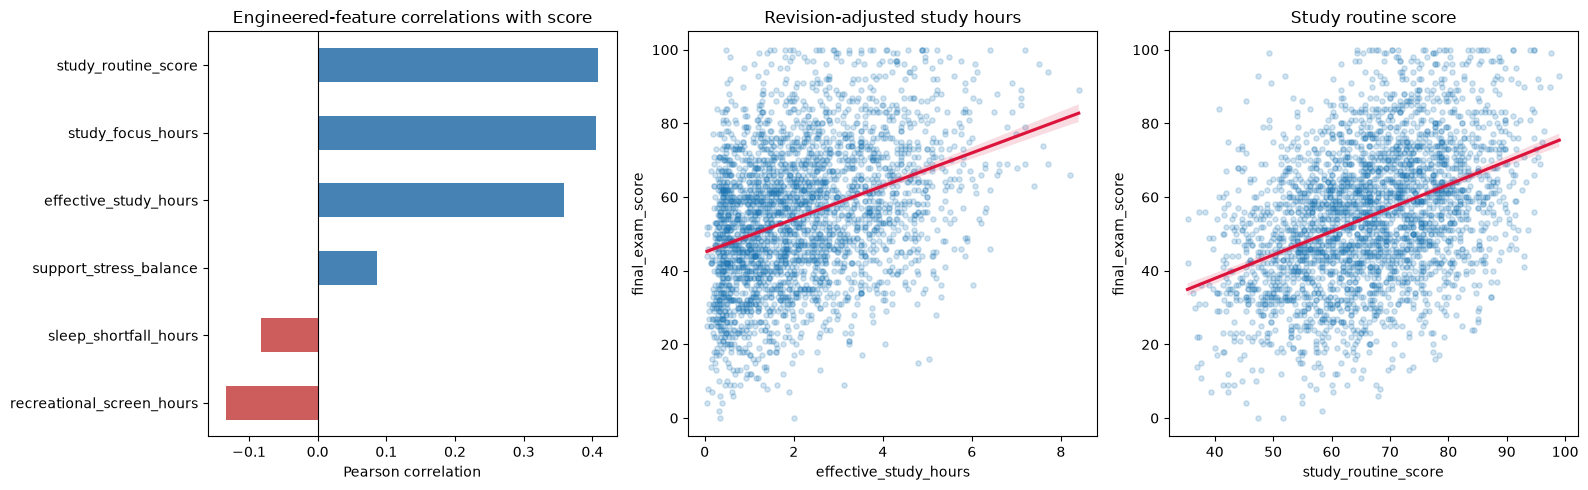

In [18]:
engineered = eda.drop(columns=["student_id", "performance_category", "final_exam_score"]).copy()
engineered["effective_study_hours"] = eda["study_hours_per_day"] * eda["revision_efficiency"] / 10
engineered["study_focus_hours"] = eda["study_hours_per_day"] * eda["focus_score"] / 10
engineered["recreational_screen_hours"] = eda["social_media_hours"] + eda["gaming_hours"]
engineered["sleep_shortfall_hours"] = (8 - eda["sleep_hours"]).clip(lower=0)
engineered["study_routine_score"] = (
    eda["assignment_completion_rate"] + eda["attendance_percentage"] + 10 * eda["consistency_score"]
) / 3
engineered["support_stress_balance"] = eda["family_support"] - eda["financial_stress"]

engineered_features = [
    "effective_study_hours", "study_focus_hours", "recreational_screen_hours",
    "sleep_shortfall_hours", "study_routine_score", "support_stress_balance"
]
feature_correlations = (
    engineered[engineered_features].assign(final_exam_score=eda["final_exam_score"])
    .corr()["final_exam_score"].drop("final_exam_score").sort_values()
)
display(engineered[engineered_features].describe().T.round(2))
display(feature_correlations.rename("correlation with final_exam_score").to_frame().round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
feature_correlations.plot(kind="barh", ax=axes[0], color=["indianred" if value < 0 else "steelblue" for value in feature_correlations])
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Engineered-feature correlations with score")
axes[0].set_xlabel("Pearson correlation")
sns.regplot(data=engineered.assign(final_exam_score=eda["final_exam_score"]), x="effective_study_hours", y="final_exam_score", scatter_kws={"alpha": 0.2, "s": 14}, line_kws={"color": "crimson"}, ax=axes[1])
axes[1].set_title("Revision-adjusted study hours")
sns.regplot(data=engineered.assign(final_exam_score=eda["final_exam_score"]), x="study_routine_score", y="final_exam_score", scatter_kws={"alpha": 0.2, "s": 14}, line_kws={"color": "crimson"}, ax=axes[2])
axes[2].set_title("Study routine score")
fig.tight_layout()
fig.savefig(eda_plot_dir / "engineered_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [19]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
student_id,3000.0,1499.500000,866.169729,0.0,749.75,1499.5,2249.25,2999.0
age,3000.0,19.030333,2.553217,15.0,17.00,19.0,21.00,23.0
study_hours_per_day,3000.0,3.988767,1.503377,0.5,2.90,4.0,5.00,8.8
deep_work_sessions,3000.0,3.511667,2.297743,0.0,1.00,4.0,6.00,7.0
assignment_completion_rate,3000.0,69.926333,17.562794,40.0,55.00,70.0,85.00,100.0
attendance_percentage,3000.0,74.558000,14.473048,50.0,62.00,74.0,87.00,100.0
social_media_hours,2940.0,2.949422,1.510306,0.0,1.90,2.9,4.00,8.9
doomscrolling_before_sleep,3000.0,0.493000,0.500034,0.0,0.00,0.0,1.00,1.0
notification_distractions,3000.0,61.961667,33.125156,5.0,32.00,62.0,91.00,119.0
ai_tool_usage_hours,3000.0,1.538933,0.925619,0.0,0.90,1.5,2.10,5.0


In [20]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   student_id                   3000 non-null   int64  
 1   age                          3000 non-null   int64  
 2   gender                       3000 non-null   str    
 3   city_type                    3000 non-null   str    
 4   study_hours_per_day          3000 non-null   float64
 5   deep_work_sessions           3000 non-null   int64  
 6   assignment_completion_rate   3000 non-null   int64  
 7   attendance_percentage        3000 non-null   int64  
 8   social_media_hours           2940 non-null   float64
 9   doomscrolling_before_sleep   3000 non-null   int64  
 10  notification_distractions    3000 non-null   int64  
 11  ai_tool_usage_hours          3000 non-null   float64
 12  gaming_hours                 3000 non-null   float64
 13  stress_level                 

In [21]:
data = pd.read_csv("student_performance_dataset.csv", skipinitialspace=True)
duplicate_rows = data.duplicated().sum()
print(f"Duplicate rows: {duplicate_rows}")
data = data.drop(columns=["performance_category"]).dropna().copy()
data.isna().sum()

Duplicate rows: 0


student_id                     0
age                            0
gender                         0
city_type                      0
study_hours_per_day            0
deep_work_sessions             0
assignment_completion_rate     0
attendance_percentage          0
social_media_hours             0
doomscrolling_before_sleep     0
notification_distractions      0
ai_tool_usage_hours            0
gaming_hours                   0
stress_level                   0
motivation_level               0
focus_score                    0
procrastination_index          0
mental_state                   0
sleep_hours                    0
caffeine_intake                0
physical_activity_hours        0
internet_quality               0
family_support                 0
financial_stress               0
learning_style                 0
career_goal                    0
productivity_after_midnight    0
revision_efficiency            0
burnout_risk                   0
consistency_score              0
final_exam

In [22]:
data_categorical = data.select_dtypes(include='str')
data_categorical.nunique()

gender            2
city_type         3
mental_state      4
learning_style    4
career_goal       5
dtype: int64

<Axes: >

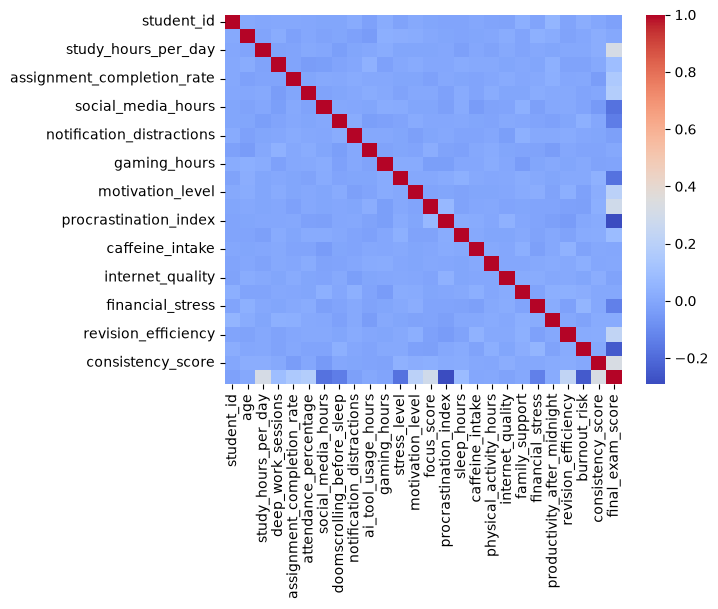

In [23]:
sns.heatmap(data.select_dtypes(include='number').corr(), annot=False, cmap='coolwarm')

In [24]:
data_numeric = pd.get_dummies(data, drop_first=False)
data_numeric.head()

,student_id,age,study_hours_per_day,deep_work_sessions,assignment_completion_rate,attendance_percentage,social_media_hours,doomscrolling_before_sleep,notification_distractions,ai_tool_usage_hours,...,mental_state_Focused,learning_style_Audio,learning_style_Practical,learning_style_Reading,learning_style_Visual,career_goal_Arts,career_goal_Business,career_goal_Engineering,career_goal_Medical,career_goal_Research
0,0,21,3.2,7,100,70,3.8,0,107,0.6,...,False,True,False,False,False,False,False,True,False,False
1,1,19,3.9,2,46,70,2.6,1,93,1.5,...,False,False,True,False,False,False,True,False,False,False
2,2,16,4.3,7,54,57,4.3,1,82,0.5,...,False,False,False,False,True,False,False,True,False,False
3,3,19,5.3,1,78,90,1.7,0,27,1.4,...,False,False,False,True,False,False,False,False,True,False
4,4,17,4.1,3,100,81,2.6,0,8,1.3,...,True,False,False,False,True,False,False,False,True,False


In [25]:
def get_top_correlations(df, n=3):
    # Calculate the correlation matrix
    corr_matrix = df.corr()
    
    results = []
    for col in corr_matrix.columns:
        # Get absolute correlations, sort descending, drop the feature itself
        top_n = corr_matrix[col].abs().sort_values(ascending=False).drop(col).head(n)
        
        # Create a dictionary for the row
        row = {'Feature': col}
        for i, (feature_name, _) in enumerate(top_n.items(), 1):
            # Grab the actual (positive or negative) correlation value
            actual_corr = corr_matrix.loc[col, feature_name]
            row[f'Top_{i}_Feature'] = feature_name
            row[f'Top_{i}_Corr'] = round(actual_corr, 4)
            
        results.append(row)
        
    return pd.DataFrame(results)

# RUN IT: Replace 'df_encoded' with your actual encoded dataframe variable
top_corr_df = get_top_correlations(data_numeric, n=5)

# Display the resulting dataframe
display(top_corr_df)


,Feature,Top_1_Feature,Top_1_Corr,Top_2_Feature,Top_2_Corr,Top_3_Feature,Top_3_Corr,Top_4_Feature,Top_4_Corr,Top_5_Feature,Top_5_Corr
0,student_id,mental_state_Distracted,0.0738,mental_state_Focused,-0.0659,productivity_after_midnight,0.0515,mental_state_Balanced,-0.0376,mental_state_Burnout,0.0274
1,age,mental_state_Burnout,-0.0503,ai_tool_usage_hours,-0.0404,career_goal_Research,-0.0368,financial_stress,0.0347,learning_style_Reading,-0.0317
2,study_hours_per_day,final_exam_score,0.3170,gender_Female,0.0404,gender_Male,-0.0404,doomscrolling_before_sleep,-0.0339,city_type _Semi-Urban,-0.0283
3,deep_work_sessions,final_exam_score,0.0960,ai_tool_usage_hours,0.0408,attendance_percentage,-0.0358,mental_state_Burnout,0.0353,productivity_after_midnight,0.0334
4,assignment_completion_rate,final_exam_score,0.1513,consistency_score,-0.0372,career_goal_Arts,-0.0342,mental_state_Burnout,0.0306,productivity_after_midnight,0.0299
5,attendance_percentage,final_exam_score,0.1761,city_type _Urban,0.0475,city_type _Semi-Urban,-0.0364,learning_style_Practical,0.0362,deep_work_sessions,-0.0358
6,social_media_hours,final_exam_score,-0.1783,mental_state_Distracted,0.0722,consistency_score,-0.0466,caffeine_intake,-0.0415,mental_state_Focused,-0.0379
7,doomscrolling_before_sleep,final_exam_score,-0.1430,gender_Female,-0.0498,gender_Male,0.0498,burnout_risk,0.0346,study_hours_per_day,-0.0339
8,notification_distractions,internet_quality,-0.0318,family_support,0.0318,final_exam_score,-0.0275,motivation_level,-0.0270,mental_state_Balanced,0.0258
9,ai_tool_usage_hours,deep_work_sessions,0.0408,age,-0.0404,productivity_after_midnight,-0.0384,doomscrolling_before_sleep,-0.0331,mental_state_Focused,-0.0260


In [26]:
def model_building(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    ss = StandardScaler()
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    X_train_ss = ss.fit_transform(X_train)
    X_test_ss = ss.transform(X_test)
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.plot(y_test.values, label='Actual', color='blue')
    ax.plot(y_pred, label='Predicted', color='red')
    ax.set(xlabel='x data', ylabel='y data')
    ax.set_title('Model Performance')
    ax.legend()
    plt.show()
    #residual plot
    residuals = y_test - y_pred
    plt.figure(figsize=(10, 8))
    sns.residplot(x=y_pred, y=residuals, lowess=False, color='blue')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title('Residual Plot')
    plt.show()
    print('R2 Score of the model:', r2)
    print('Adjusted R2 Score of the model:', 1 - (1 - r2) * (len(y_test) - 1) / (len(y_test) - X_test.shape[1] - 1))
    print('RMSE of the model:', rmse)
    print('Mean Absolute Error of the model:', mean_absolute_error(y_test, y_pred))


In [27]:
def get_R2_features(model,test=True): 
    #X: global  
    features=list(X)
    
    
    R_2_train=[]
    R_2_test=[]

    for feature in features:
        model.fit(X_train[[feature]],y_train)
        
        R_2_test.append(model.score(X_test[[feature]],y_test))
        R_2_train.append(model.score(X_train[[feature]],y_train))
        
    plt.bar(features,R_2_train,label="Train")
    plt.bar(features,R_2_test,label="Test")
    plt.xticks(rotation=90)
    plt.ylabel("$R^2$")
    plt.legend()
    plt.show()
    print("Training R^2 mean value {} Testing R^2 mean value {} ".format(str(np.mean(R_2_train)),str(np.mean(R_2_test))) )
    print("Training R^2 max value {} Testing R^2 max value {} ".format(str(np.max(R_2_train)),str(np.max(R_2_test))) )

In [28]:
X = data_numeric.drop('final_exam_score', axis=1)
Y = data_numeric['final_exam_score']
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.3, random_state=42)
X.isna().sum()

student_id                       0
age                              0
study_hours_per_day              0
deep_work_sessions               0
assignment_completion_rate       0
attendance_percentage            0
social_media_hours               0
doomscrolling_before_sleep       0
notification_distractions        0
ai_tool_usage_hours              0
gaming_hours                     0
stress_level                     0
motivation_level                 0
focus_score                      0
procrastination_index            0
sleep_hours                      0
caffeine_intake                  0
physical_activity_hours          0
internet_quality                 0
family_support                   0
financial_stress                 0
productivity_after_midnight      0
revision_efficiency              0
burnout_risk                     0
consistency_score                0
gender_Female                    0
gender_Male                      0
city_type _Rural                 0
city_type _Semi-Urba

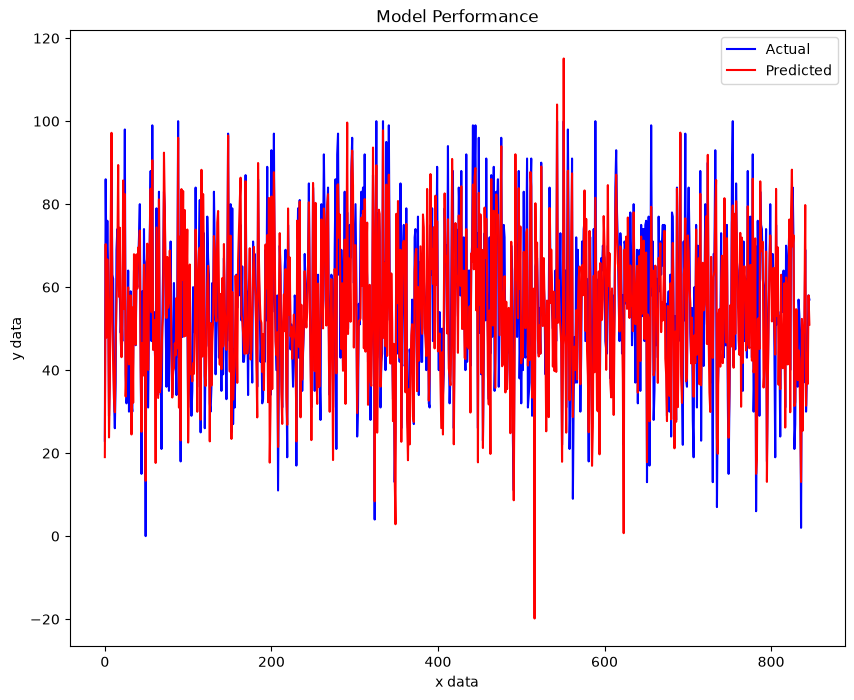

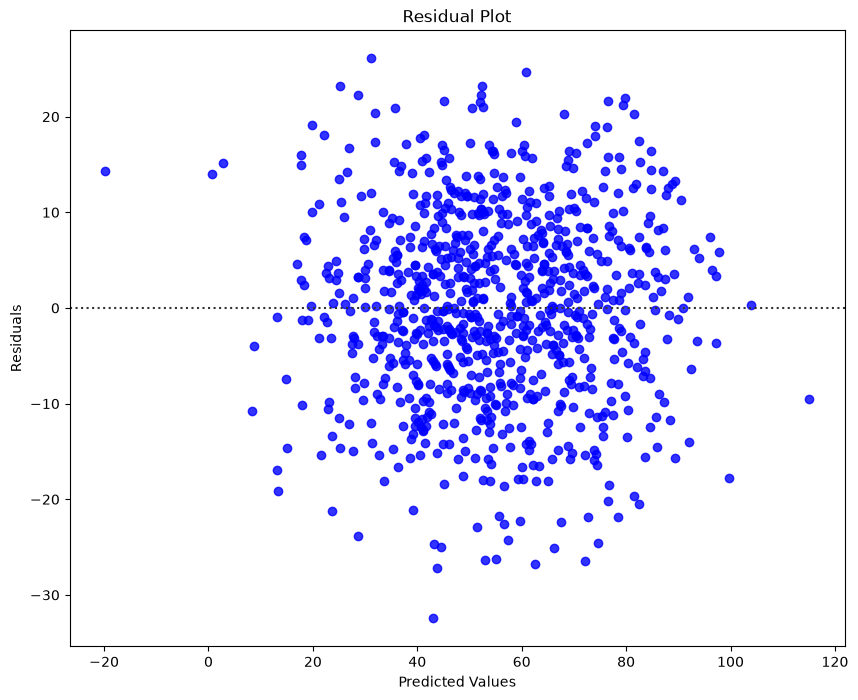

R2 Score of the model: 0.7068214565782607
Adjusted R2 Score of the model: 0.691121982895652
RMSE of the model: 10.28241899991471
Mean Absolute Error of the model: 8.230133859141176


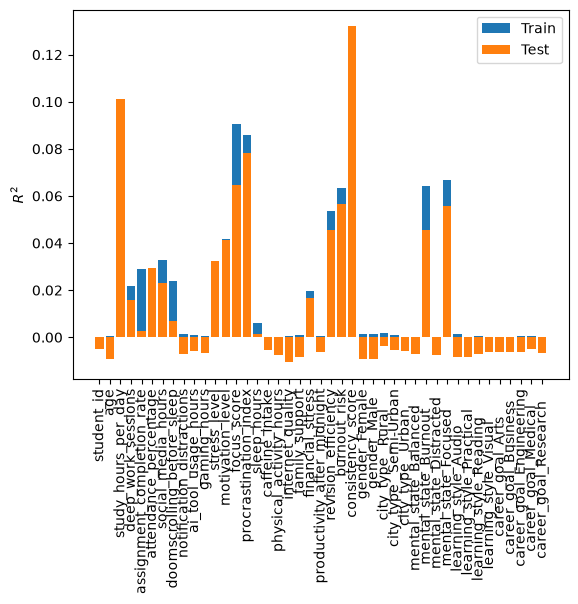

Training R^2 mean value 0.020033835937616262 Testing R^2 mean value 0.013213471714085285 
Training R^2 max value 0.09696300492679721 Testing R^2 max value 0.13195520396799498 


In [29]:

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('linear', LinearRegression())])

model_building(pipe, X_train, y_train, X_test, y_test)
get_R2_features(pipe, test=True)





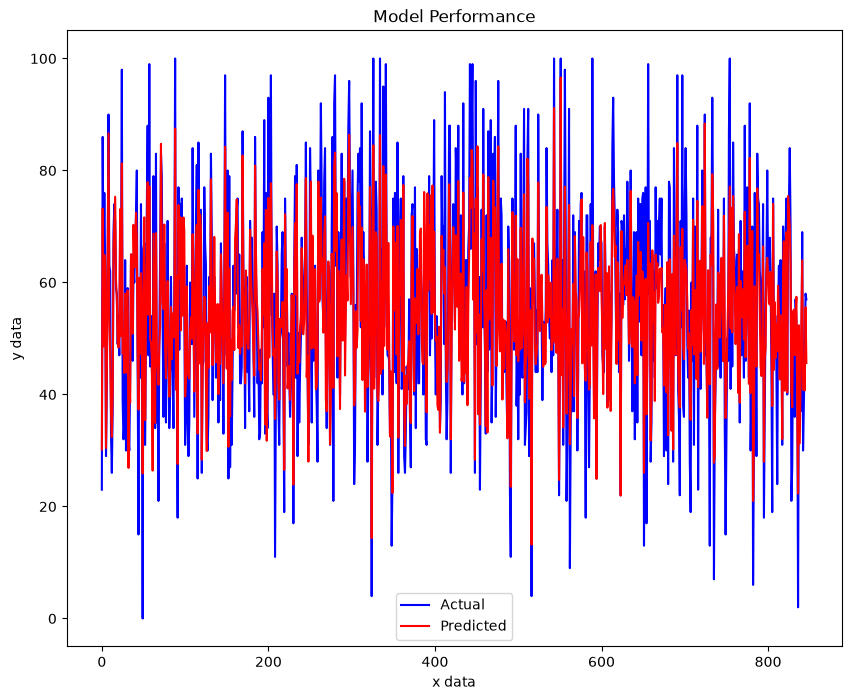

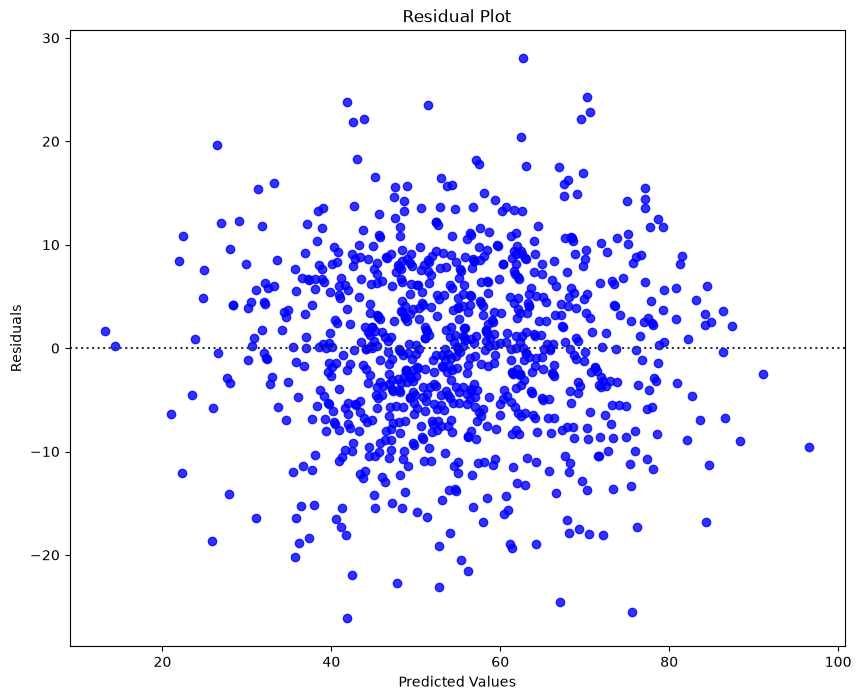

R2 Score of the model: 0.7594226274509847
Adjusted R2 Score of the model: 0.7465399038898294
RMSE of the model: 9.314436672279424
Mean Absolute Error of the model: 7.4057180928402095


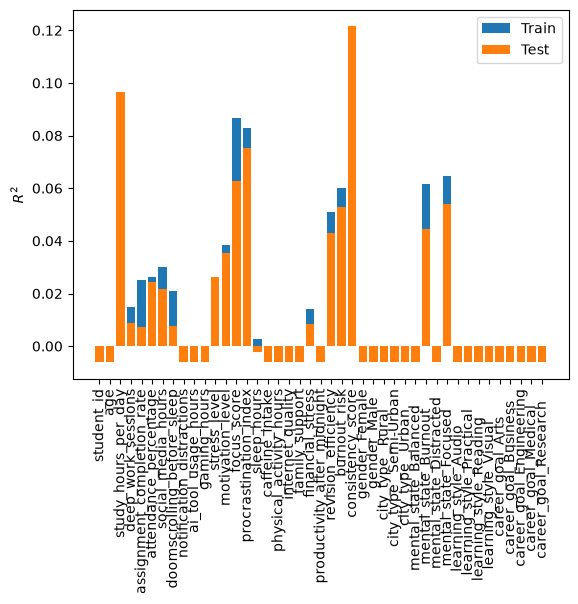

Training R^2 mean value 0.01832627575562058 Testing R^2 mean value 0.012251178663699082 
Training R^2 max value 0.09385264166742291 Testing R^2 max value 0.12145667379401681 
Best alpha: 0.12648552168552957
Best degree: 1
Best score: 0.8053696069734171


In [30]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('lasso', Lasso())
])

model_building(pipe, X_train, y_train, X_test, y_test)
get_R2_features(pipe, test=True)

alphas = np.logspace(-4, 0, 50)

param_grid = {
    'lasso__alpha': alphas,
    'poly__degree': [1, 2, 3]
}

search = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
search.fit(X_train, y_train)

print("Best alpha:", search.best_params_['lasso__alpha'])
print("Best degree:", search.best_params_['poly__degree'])
print("Best score:", search.best_score_)

In [31]:
search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...o', Lasso())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'lasso__alpha': array([1.0000...00000000e+00]), 'poly__degree': [1, 2, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbos

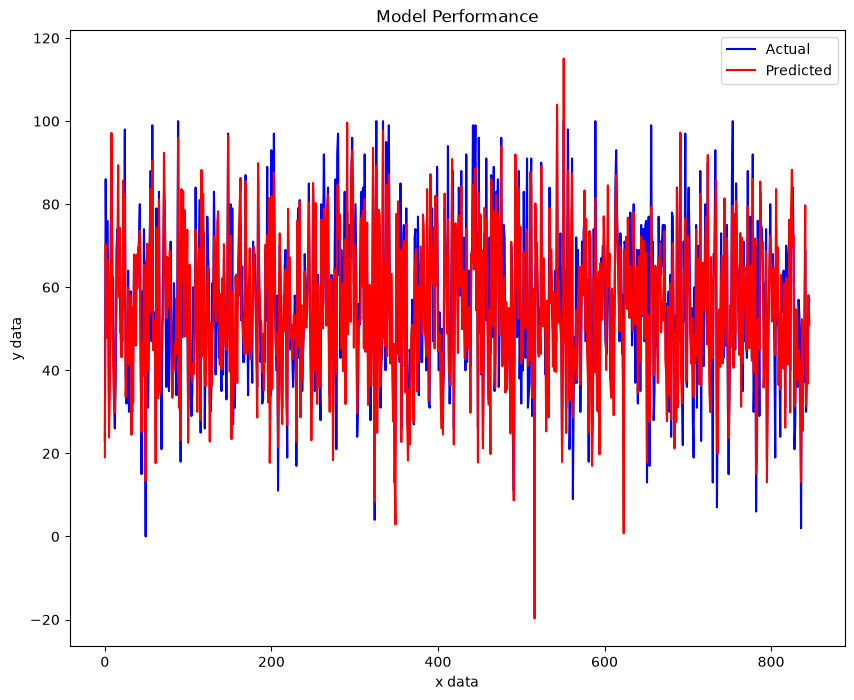

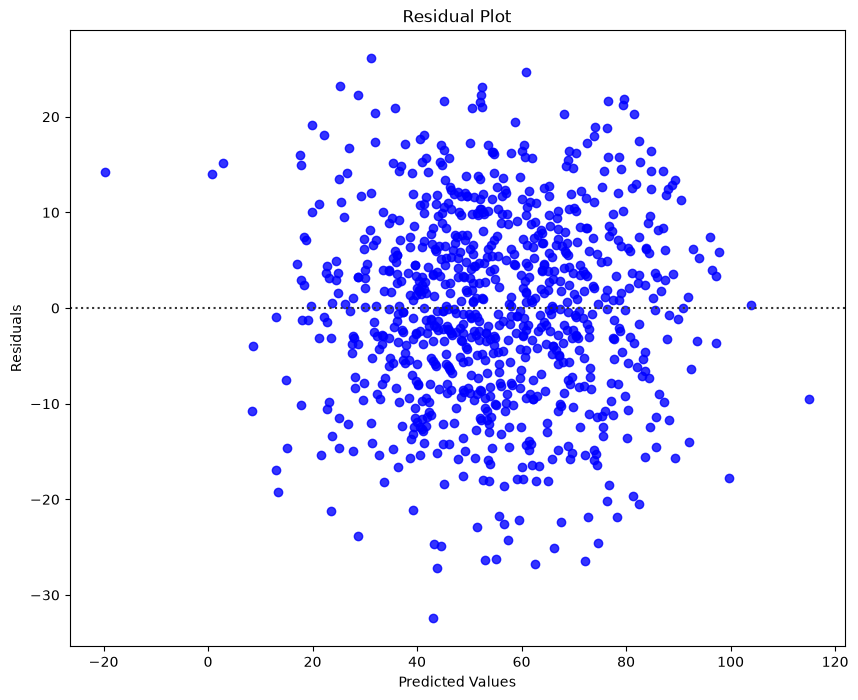

R2 Score of the model: 0.7071261959803059
Adjusted R2 Score of the model: 0.6914430408460011
RMSE of the model: 10.27707366860342
Mean Absolute Error of the model: 8.226197016428856


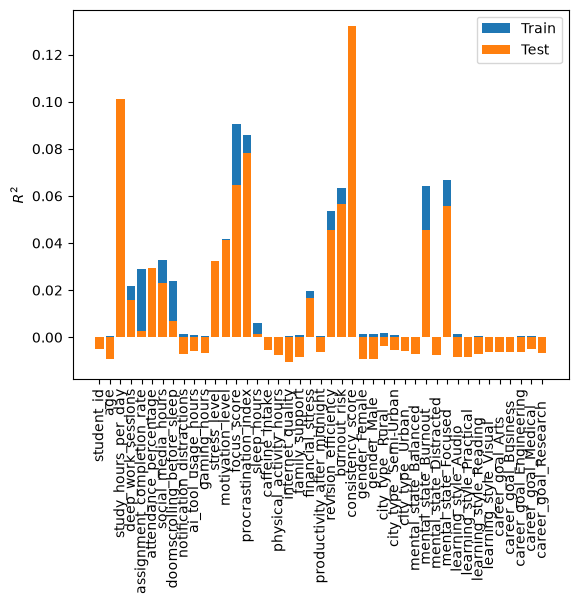

Training R^2 mean value 0.0200338313772378 Testing R^2 mean value 0.01321317970617355 
Training R^2 max value 0.09696298024936023 Testing R^2 max value 0.1319330064617963 
Best alpha: 1
Best degree: 1
Best score: 0.8035096883480406


In [32]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('ridge', Ridge())
])

model_building(pipe, X_train, y_train, X_test, y_test)
get_R2_features(pipe, test=True)

alphas = np.logspace(-4, 0, 50)

param_grid = {
    'ridge__alpha': [1],
    'poly__degree': [1]
}

search = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
search.fit(X_train, y_train)

print("Best alpha:", search.best_params_['ridge__alpha'])
print("Best degree:", search.best_params_['poly__degree'])
print("Best score:", search.best_score_)

In [33]:
search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...e', Ridge())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'poly__degree': [1], 'ridge__alpha': [1]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during f

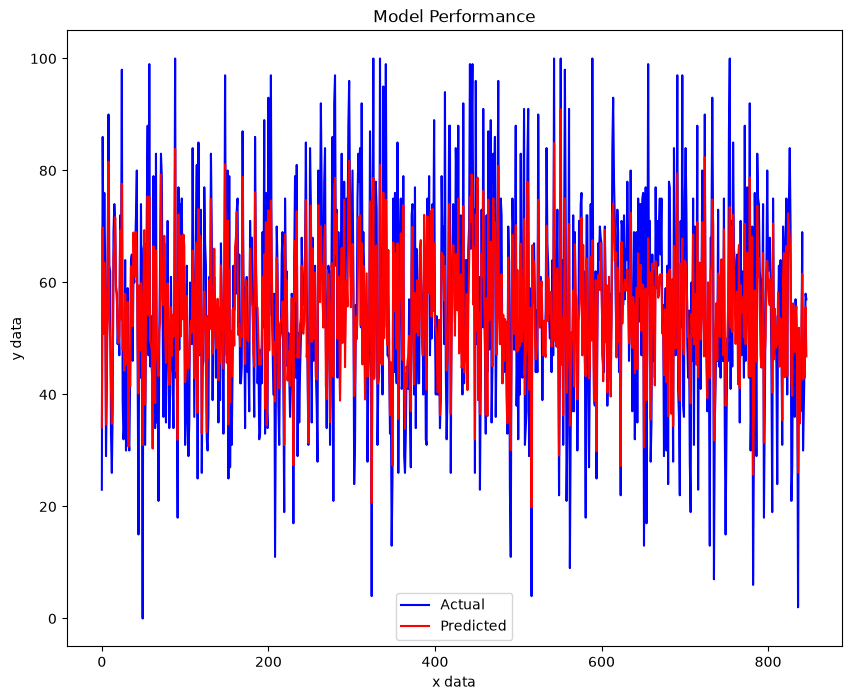

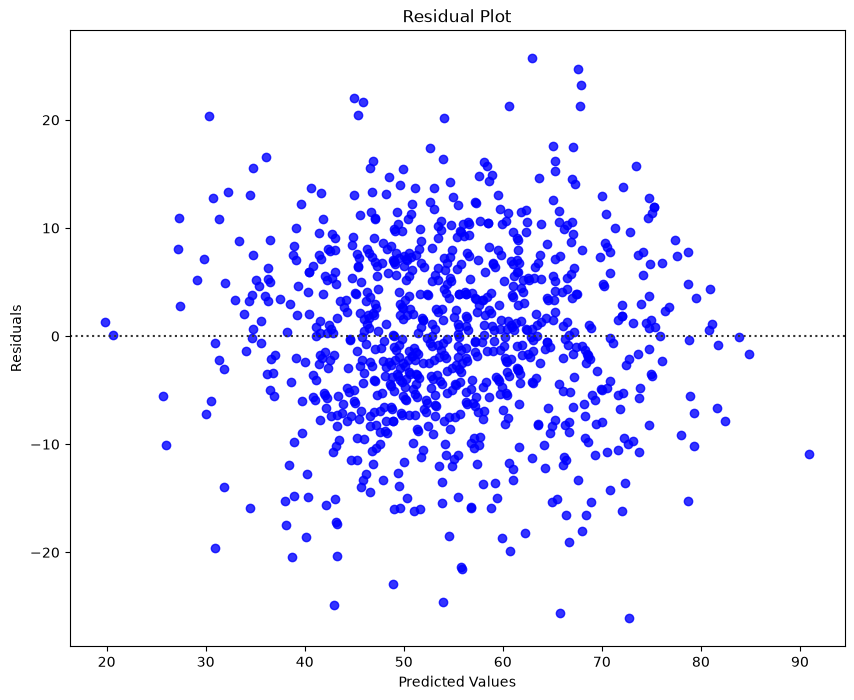

R2 Score of the model: 0.7103338091960099
Adjusted R2 Score of the model: 0.6948224191529568
RMSE of the model: 10.220640430042465
Mean Absolute Error of the model: 8.15158430308415


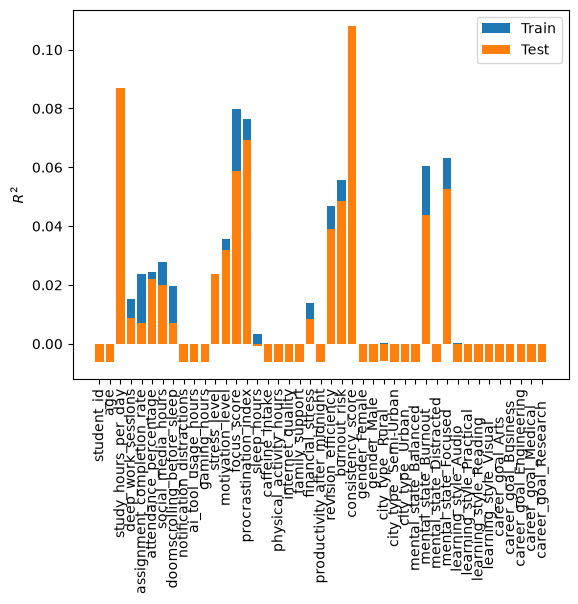

Training R^2 mean value 0.01719700919781783 Testing R^2 mean value 0.0110063584016603 
Training R^2 max value 0.08659682240932043 Testing R^2 max value 0.10787249675247146 
Best alpha: 0.05963
Best degree: 1
Best l1_ratio: 0.7
Best score: 0.8043017741457898


In [34]:
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2)),
    ('elasticnet', ElasticNet(l1_ratio=0.7))
])

model_building(pipe, X_train, y_train, X_test, y_test)
get_R2_features(pipe, test=True)

alphas = np.logspace(-4, 0, 50)

param_grid = {
    'elasticnet__alpha': [0.05963],
    'elasticnet__l1_ratio': [0.7],
    'poly__degree': [1]
}

search = GridSearchCV(pipe, param_grid, cv=5, n_jobs=-1)
search.fit(X_train, y_train)

print("Best alpha:", search.best_params_['elasticnet__alpha'])
print("Best degree:", search.best_params_['poly__degree'])
print("Best l1_ratio:", search.best_params_['elasticnet__l1_ratio'])
print("Best score:", search.best_score_)

In [35]:
search

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._ratio=0.7))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'elasticnet__alpha': [0.05963], 'elasticnet__l1_ratio': [0.7], 'poly__degree': [1]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the v